# Dataset exploration


In [21]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt


PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "requirements.txt").is_file() and (p / "data").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run this notebook from the cloned project folder or notebooks/.")


In [22]:
image_dir = PROJECT_ROOT / "data/data/OCR-D-IMG"

image_paths = sorted(image_dir.glob("*.tif"))

print("Number of images:", len(image_paths))

for path in image_paths:
    print(path.name)

Number of images: 4
bebel_frau_1879_0146.tif
bebel_frau_1879_0168.tif
bebel_frau_1879_0176.tif
bebel_frau_1879_0186.tif


Image dimensions: (3068, 4660)
Image mode: 1


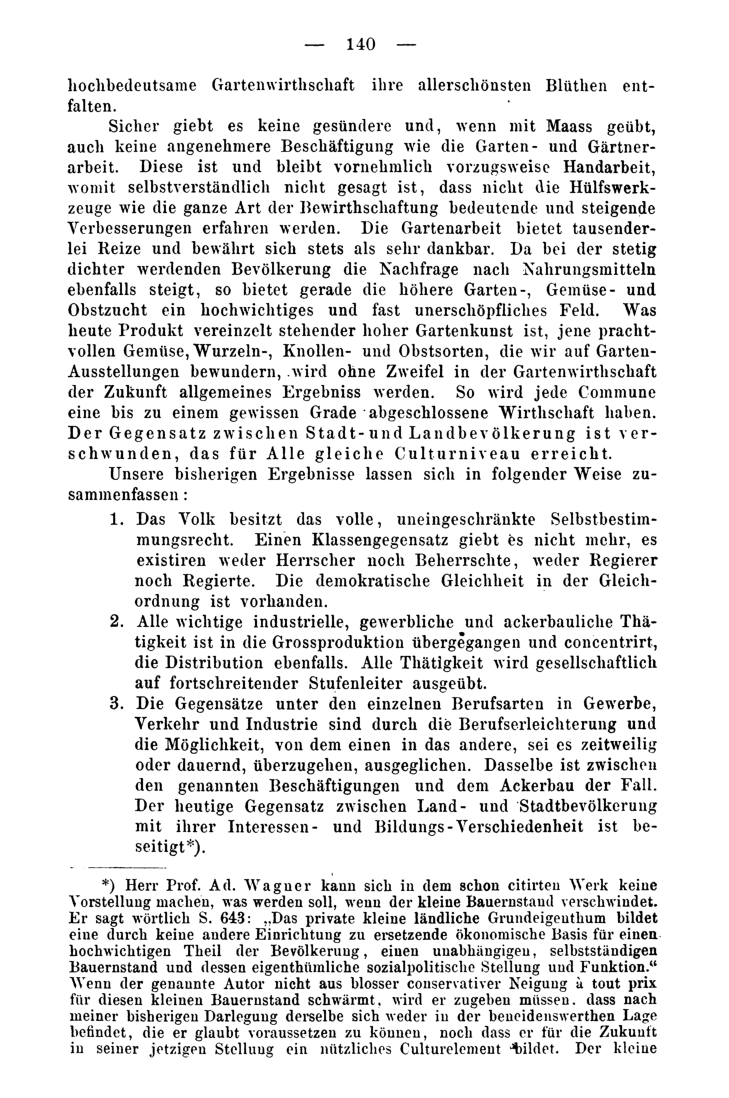

In [23]:
image = Image.open(image_paths[0])

print("Image dimensions:", image.size)
print("Image mode:", image.mode)

plt.figure(figsize=(10, 14))
plt.imshow(image, cmap="gray")
plt.axis("off")
plt.show()

In [24]:
from lxml import etree

dataset_dir = PROJECT_ROOT / "data/data/OCR-D-GT-SEG-LINE"

xml_files = sorted(dataset_dir.rglob("*.xml"))

for path in xml_files:
    print(path.relative_to(dataset_dir))

bebel_frau_1879_0146.xml
bebel_frau_1879_0168.xml
bebel_frau_1879_0176.xml
bebel_frau_1879_0186.xml


In [25]:
line_xml = next(
    p for p in xml_files
    if "SEG-LINE" in str(p)
)

tree = etree.parse(str(line_xml))
root = tree.getroot()

print("Root element:", root.tag)
print("Root attributes:", root.attrib)

for element in list(root)[:5]:
    print(element.tag)

Root element: {http://schema.primaresearch.org/PAGE/gts/pagecontent/2019-07-15}PcGts
Root attributes: {'{http://www.w3.org/2001/XMLSchema-instance}schemaLocation': 'http://schema.primaresearch.org/PAGE/gts/pagecontent/2019-07-15 http://schema.primaresearch.org/PAGE/gts/pagecontent/2019-07-15/pagecontent.xsd', 'pcGtsId': 'pc-bebel_frau_1879_0146'}
{http://schema.primaresearch.org/PAGE/gts/pagecontent/2019-07-15}Metadata
{http://schema.primaresearch.org/PAGE/gts/pagecontent/2019-07-15}Page


## Exploring PAGE-XML annotations

In [26]:
ns = {
    "page": "http://schema.primaresearch.org/PAGE/gts/pagecontent/2019-07-15"
}

page = root.find("page:Page", ns)

regions = page.findall(".//page:TextRegion", ns)
lines = page.findall(".//page:TextLine", ns)

print("Number of text regions:", len(regions))
print("Number of text lines:", len(lines))

Number of text regions: 5
Number of text lines: 50


In [27]:
first_line = lines[0]

print("Line ID:", first_line.get("id"))

for child in first_line:
    print(child.tag.split("}")[-1], child.attrib)

Line ID: l7
Coords {'points': '1562,119 1562,120 1563,120 1563,121 1564,121 1564,122 1566,122 1566,123 1568,123 1568,124 1569,124 1569,125 1570,125 1570,126 1571,126 1571,127 1572,127 1572,129 1573,129 1573,131 1574,131 1574,132 1575,132 1575,135 1576,135 1576,140 1577,140 1577,148 1679,148 1679,147 1752,147 1752,148 1754,148 1754,149 1755,149 1755,150 1754,150 1754,152 1746,152 1746,153 1577,153 1577,155 1576,155 1576,157 1575,157 1575,160 1574,160 1574,162 1573,162 1573,163 1572,163 1572,165 1571,165 1571,167 1570,167 1570,168 1569,168 1569,169 1568,169 1568,170 1566,170 1566,171 1564,171 1564,172 1559,172 1559,173 1554,173 1554,172 1552,172 1552,171 1458,171 1458,153 1353,153 1353,154 1334,154 1334,155 1281,155 1281,154 1274,154 1274,150 1276,150 1276,149 1278,149 1278,148 1356,148 1356,149 1458,149 1458,128 1459,128 1459,127 1463,127 1463,126 1466,126 1466,125 1467,125 1467,124 1469,124 1469,123 1470,123 1470,122 1518,122 1518,121 1553,121 1553,120 1556,120 1556,119'}
TextEquiv {}


In [28]:
for line in lines[:5]:
    text_element = line.find(".//page:Unicode", ns)

    if text_element is not None:
        print(line.get("id"), ":", text_element.text)
    else:
        print(line.get("id"), ": No transcription found")

l7 : — 140 —
l11 : hochbedeutsame Gartenwirthschaft ihre allerschönsten Blüthen ent-
l12 : falten.
l14 : Sicher giebt es keine gesündere und, wenn mit Maass geübt,
l16 : auch keine angenehmere Beschäftigung wie die Garten- und Gärtner-


## Visualizing text-line segmentation

In [29]:
coords_element = first_line.find("page:Coords", ns)

points_string = coords_element.get("points")

print(points_string[:150])

1562,119 1562,120 1563,120 1563,121 1564,121 1564,122 1566,122 1566,123 1568,123 1568,124 1569,124 1569,125 1570,125 1570,126 1571,126 1571,127 1572,1


In [30]:
points = []

for pair in points_string.split():
    x, y = pair.split(",")
    points.append((int(x), int(y)))

print(points[:5])

[(1562, 119), (1562, 120), (1563, 120), (1563, 121), (1564, 121)]


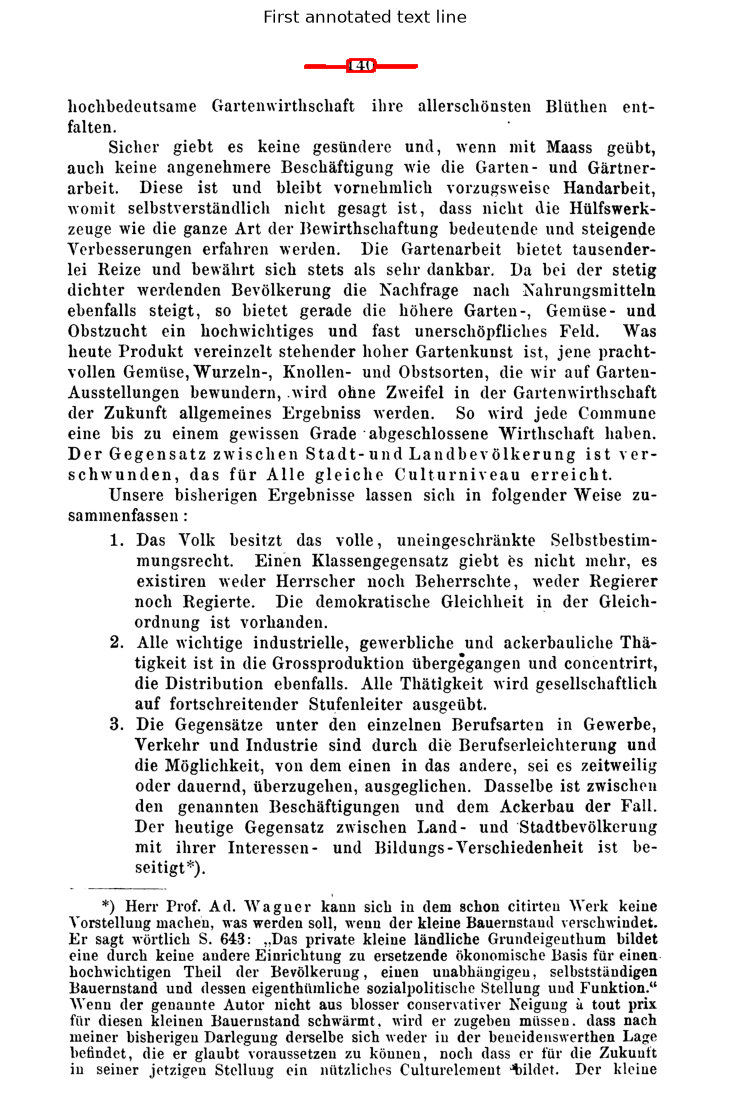

In [31]:
from matplotlib.patches import Polygon

fig, ax = plt.subplots(figsize=(10, 14))

ax.imshow(image, cmap="gray")

polygon = Polygon(
    points,
    closed=True,
    fill=False,
    edgecolor="red",
    linewidth=2
)

ax.add_patch(polygon)

ax.set_title("First annotated text line")
ax.axis("off")

plt.show()

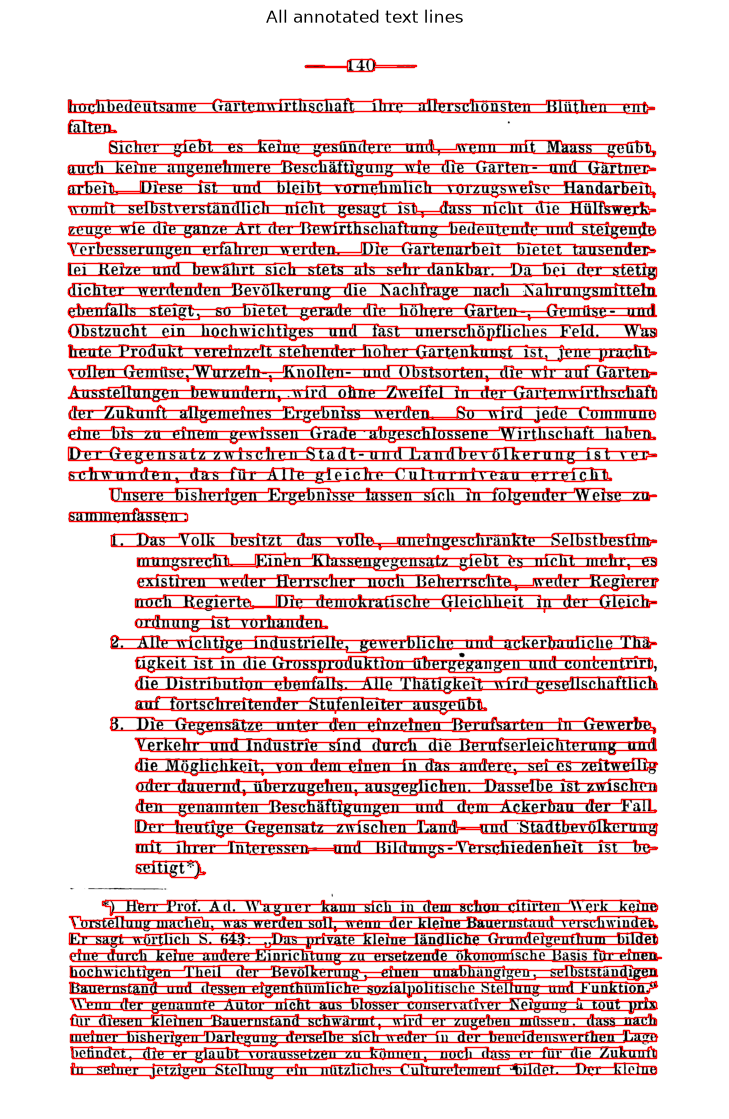

In [32]:
from matplotlib.patches import Polygon

fig, ax = plt.subplots(figsize=(10, 14))
ax.imshow(image, cmap="gray")

for line in lines:
    coords = line.find("page:Coords", ns)

    if coords is None:
        continue

    points = []

    for pair in coords.get("points").split():
        x, y = pair.split(",")
        points.append((int(x), int(y)))

    polygon = Polygon(
        points,
        closed=True,
        fill=False,
        edgecolor="red",
        linewidth=1
    )

    ax.add_patch(polygon)

ax.set_title("All annotated text lines")
ax.axis("off")
plt.show()

Line ID: l11


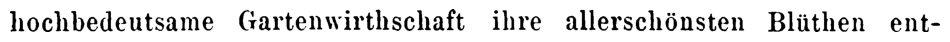

In [33]:
selected_line = lines[1]

coords = selected_line.find("page:Coords", ns)

points = [
    tuple(map(int, pair.split(",")))
    for pair in coords.get("points").split()
]

xs = [x for x, y in points]
ys = [y for x, y in points]

x_min, x_max = min(xs), max(xs)
y_min, y_max = min(ys), max(ys)

cropped_line = image.crop(
    (x_min, y_min, x_max, y_max)
)

print("Line ID:", selected_line.get("id"))

plt.figure(figsize=(12, 3))
plt.imshow(cropped_line, cmap="gray")
plt.axis("off")
plt.show()

In [34]:
text_element = selected_line.find(
    ".//page:Unicode", ns
)

ground_truth = (
    text_element.text
    if text_element is not None
    else None
)

print("Ground truth:", ground_truth)

Ground truth: hochbedeutsame Gartenwirthschaft ihre allerschönsten Blüthen ent-


## Creating a line-level dataset

In [35]:
records = []

In [ ]:
from pathlib import Path

output_dir = PROJECT_ROOT / "data/processed/line_images"
output_dir.mkdir(parents=True, exist_ok=True)

records = []

page_id = image_paths[0].stem

for line in lines:
    line_id = line.get("id")

    coords = line.find("page:Coords", ns)
    text_element = line.find(".//page:Unicode", ns)

    if coords is None or text_element is None:
        continue

    points = [
        tuple(map(int, pair.split(",")))
        for pair in coords.get("points").split()
    ]

    if not points:
        continue

    xs = [x for x, y in points]
    ys = [y for x, y in points]

    x_min, x_max = min(xs), max(xs)
    y_min, y_max = min(ys), max(ys)

    x_min = max(0, x_min)
    y_min = max(0, y_min)
    x_max = min(image.width, x_max)
    y_max = min(image.height, y_max)

    if x_max <= x_min or y_max <= y_min:
        continue

    cropped_line = image.crop(
        (x_min, y_min, x_max, y_max)
    )

    filename = f"{page_id}_{line_id}.png"
    save_path = output_dir / filename

    cropped_line.save(save_path)

    records.append({
        "page_id": page_id,
        "line_id": line_id,
        "image_path": save_path.relative_to(PROJECT_ROOT).as_posix(),
        "ground_truth": text_element.text,
        "x_min": x_min,
        "y_min": y_min,
        "x_max": x_max,
        "y_max": y_max
    })

print("Successfully extracted:", len(records), "lines")

Successfully extracted: 50 lines


In [38]:
import pandas as pd

df = pd.DataFrame(records)

print(df.head().to_string())

print("Total extracted lines:", len(df))

,page_id,line_id,image_path,ground_truth,x_min,y_min,x_max,y_max
0,bebel_frau_1879_0146,l7,../data/processed/line_images/bebel_frau_1879_...,— 140 —,1274,119,1755,173
1,bebel_frau_1879_0146,l11,../data/processed/line_images/bebel_frau_1879_...,hochbedeutsame Gartenwirthschaft ihre allersch...,250,291,2785,353
2,bebel_frau_1879_0146,l12,../data/processed/line_images/bebel_frau_1879_...,falten.,250,383,456,441
3,bebel_frau_1879_0146,l14,../data/processed/line_images/bebel_frau_1879_...,"Sicher giebt es keine gesündere und, wenn mit ...",429,468,2787,543
4,bebel_frau_1879_0146,l16,../data/processed/line_images/bebel_frau_1879_...,auch keine angenehmere Beschäftigung wie die G...,249,556,2788,628


Total extracted lines: 50


In [39]:
csv_path = PROJECT_ROOT / "data/processed/line_metadata.csv"

df.to_csv(csv_path, index=False, encoding="utf-8")

print("Saved metadata to:", csv_path)

Saved metadata to: ../data/processed/line_metadata.csv


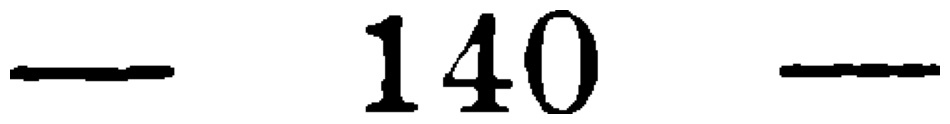

Line ID: l7
Ground truth: — 140 —
----------------------------------------------------------------------


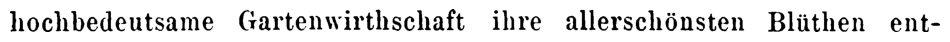

Line ID: l11
Ground truth: hochbedeutsame Gartenwirthschaft ihre allerschönsten Blüthen ent-
----------------------------------------------------------------------


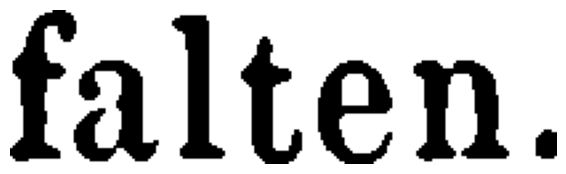

Line ID: l12
Ground truth: falten.
----------------------------------------------------------------------


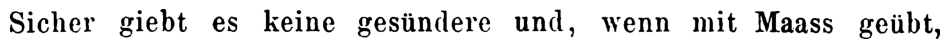

Line ID: l14
Ground truth: Sicher giebt es keine gesündere und, wenn mit Maass geübt,
----------------------------------------------------------------------


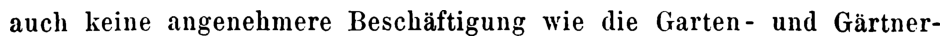

Line ID: l16
Ground truth: auch keine angenehmere Beschäftigung wie die Garten- und Gärtner-
----------------------------------------------------------------------


In [40]:
import matplotlib.pyplot as plt
from PIL import Image

for _, row in df.head(5).iterrows():
    cropped = Image.open(PROJECT_ROOT / row["image_path"])

    plt.figure(figsize=(12, 2))
    plt.imshow(cropped, cmap="gray")
    plt.axis("off")
    plt.show()

    print("Line ID:", row["line_id"])
    print("Ground truth:", row["ground_truth"])
    print("-" * 70)

## Processing the complete document dataset

In [42]:
image_map = {
    path.stem: path
    for path in image_paths
}

xml_map = {
    path.stem: path
    for path in xml_files
}

common_pages = sorted(
    set(image_map) & set(xml_map)
)

print("Matched pages:", len(common_pages))

for page_id in common_pages:
    print(page_id)

Matched pages: 4
bebel_frau_1879_0146
bebel_frau_1879_0168
bebel_frau_1879_0176
bebel_frau_1879_0186


In [ ]:

from pathlib import Path
from PIL import Image
from lxml import etree
import pandas as pd

output_dir = PROJECT_ROOT / "data/processed/line_images"
output_dir.mkdir(parents=True, exist_ok=True)

image_map = {path.stem: path for path in image_paths}
xml_map = {path.stem: path for path in xml_files}

common_pages = sorted(set(image_map) & set(xml_map))

records = []

for page_id in common_pages:

    print(f"Processing page: {page_id}")

    page_image = Image.open(image_map[page_id])

    tree = etree.parse(str(xml_map[page_id]))
    root = tree.getroot()

    page_lines = root.findall(".//page:TextLine", ns)

    print(f"  Annotated lines: {len(page_lines)}")

    for line in page_lines:

        line_id = line.get("id")

        coords = line.find("page:Coords", ns)
        text_element = line.find(".//page:Unicode", ns)

        if coords is None or text_element is None:
            continue

        if not coords.get("points"):
            continue

        points = [
            tuple(map(int, pair.split(",")))
            for pair in coords.get("points").split()
        ]

        if not points:
            continue

        xs = [x for x, y in points]
        ys = [y for x, y in points]

        x_min, x_max = min(xs), max(xs)
        y_min, y_max = min(ys), max(ys)

        x_min = max(0, x_min)
        y_min = max(0, y_min)

        x_max = min(page_image.width, x_max)
        y_max = min(page_image.height, y_max)

        if x_max <= x_min or y_max <= y_min:
            continue

        cropped_line = page_image.crop(
            (x_min, y_min, x_max, y_max)
        )

        filename = f"{page_id}_{line_id}.png"
        save_path = output_dir / filename

        cropped_line.save(save_path)

        records.append({
            "page_id": page_id,
            "line_id": line_id,
            "image_path": save_path.relative_to(PROJECT_ROOT).as_posix(),
            "ground_truth": text_element.text,
            "x_min": x_min,
            "y_min": y_min,
            "x_max": x_max,
            "y_max": y_max
        })

    page_image.close()

print("\nTotal extracted lines:", len(records))


Processing page: bebel_frau_1879_0146
  Annotated lines: 50
Processing page: bebel_frau_1879_0168
  Annotated lines: 55
Processing page: bebel_frau_1879_0176
  Annotated lines: 51
Processing page: bebel_frau_1879_0186
  Annotated lines: 8

Total extracted lines: 164


In [ ]:
df = pd.DataFrame(records)

print("Total extracted lines:", len(df))

print(df.head().to_string())

csv_path = PROJECT_ROOT / "data/processed/line_metadata.csv"

df.to_csv(csv_path, index=False, encoding="utf-8")

print("Saved to:", csv_path)

Total extracted lines: 164


,page_id,line_id,image_path,ground_truth,x_min,y_min,x_max,y_max
0,bebel_frau_1879_0146,l7,../data/processed/line_images/bebel_frau_1879_...,— 140 —,1274,119,1755,173
1,bebel_frau_1879_0146,l11,../data/processed/line_images/bebel_frau_1879_...,hochbedeutsame Gartenwirthschaft ihre allersch...,250,291,2785,353
2,bebel_frau_1879_0146,l12,../data/processed/line_images/bebel_frau_1879_...,falten.,250,383,456,441
3,bebel_frau_1879_0146,l14,../data/processed/line_images/bebel_frau_1879_...,"Sicher giebt es keine gesündere und, wenn mit ...",429,468,2787,543
4,bebel_frau_1879_0146,l16,../data/processed/line_images/bebel_frau_1879_...,auch keine angenehmere Beschäftigung wie die G...,249,556,2788,628


Saved to: ../data/processed/line_metadata.csv


In [45]:
page_summary = (
    df.groupby("page_id")
    .agg(
        extracted_lines=("line_id", "count"),
        unique_lines=("line_id", "nunique")
    )
    .reset_index()
)

print(page_summary.to_string())

,page_id,extracted_lines,unique_lines
0,bebel_frau_1879_0146,50,50
1,bebel_frau_1879_0168,55,55
2,bebel_frau_1879_0176,51,51
3,bebel_frau_1879_0186,8,8


In [46]:
missing_gt = df[
    df["ground_truth"].isna() |
    (df["ground_truth"].fillna("").str.strip() == "")
]

print("Missing or empty ground truth:", len(missing_gt))

print(missing_gt.to_string())

Missing or empty ground truth: 0


,page_id,line_id,image_path,ground_truth,x_min,y_min,x_max,y_max


In [47]:
duplicates = df.duplicated(
    subset=["page_id", "line_id"]
)

print("Duplicate page-line IDs:", duplicates.sum())

missing_images = df[
    ~df["image_path"].apply(
        lambda path: (PROJECT_ROOT / path).is_file()
    )
]

print("Missing cropped images:", len(missing_images))

Duplicate page-line IDs: 0
Missing cropped images: 0


In [48]:
for page_id in common_pages:

    with Image.open(image_map[page_id]) as img:
        actual_width, actual_height = img.size

    tree = etree.parse(str(xml_map[page_id]))
    page_element = tree.find(".//page:Page", ns)

    xml_width = int(page_element.get("imageWidth"))
    xml_height = int(page_element.get("imageHeight"))

    matches = (
        actual_width == xml_width
        and actual_height == xml_height
    )

    print(page_id)
    print("  Image:", actual_width, actual_height)
    print("  XML:  ", xml_width, xml_height)
    print("  Match:", matches)

bebel_frau_1879_0146
  Image: 3068 4660
  XML:   3068 4660
  Match: True
bebel_frau_1879_0168
  Image: 3068 4660
  XML:   3068 4660
  Match: True
bebel_frau_1879_0176
  Image: 3068 4660
  XML:   3068 4660
  Match: True
bebel_frau_1879_0186
  Image: 3068 4660
  XML:   3068 4660
  Match: True


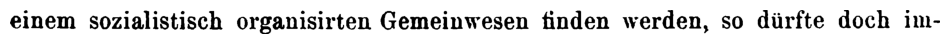

Page: bebel_frau_1879_0176
Line: l44
Ground truth: einem sozialistisch organisirten Gemeinwesen finden werden, so dürfte doch im-
----------------------------------------------------------------------


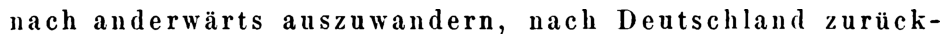

Page: bebel_frau_1879_0176
Line: l23
Ground truth: nach anderwärts auszuwandern, nach Deutschland zurück-
----------------------------------------------------------------------


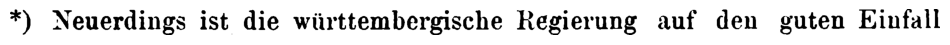

Page: bebel_frau_1879_0176
Line: l40
Ground truth: *) Neuerdings ist die württembergische Regierung auf den guten Einfall
----------------------------------------------------------------------


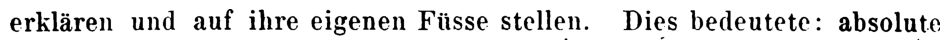

Page: bebel_frau_1879_0168
Line: l5
Ground truth: erklären und auf ihre eigenen Füsse stellen. Dies bedeutete: absolute
----------------------------------------------------------------------


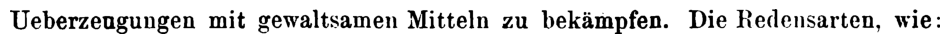

Page: bebel_frau_1879_0168
Line: l48
Ground truth: Ueberzeugungen mit gewaltsamen Mitteln zu bekämpfen. Die Redensarten, wie:
----------------------------------------------------------------------


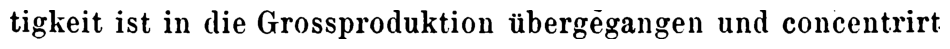

Page: bebel_frau_1879_0146
Line: l44
Ground truth: tigkeit ist in die Grossproduktion übergegangen und concentrirt,
----------------------------------------------------------------------


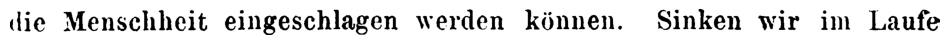

Page: bebel_frau_1879_0186
Line: l1
Ground truth: die Menschheit eingeschlagen werden können. Sinken wir im Laufe
----------------------------------------------------------------------


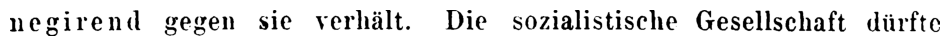

Page: bebel_frau_1879_0168
Line: l1
Ground truth: negirend gegen sie verhält. Die sozialistische Gesellschaft dürfte
----------------------------------------------------------------------


In [49]:
samples = df.sample(
    n=min(8, len(df)),
    random_state=42
)

for _, row in samples.iterrows():

    with Image.open(PROJECT_ROOT / row["image_path"]) as img:
        cropped = img.copy()

    plt.figure(figsize=(12, 2))
    plt.imshow(cropped, cmap="gray")
    plt.axis("off")
    plt.show()

    print("Page:", row["page_id"])
    print("Line:", row["line_id"])
    print("Ground truth:", row["ground_truth"])
    print("-" * 70)

,crop_width,crop_height
count,164.000000,164.000000
mean,2312.768293,68.993902
std,526.547787,5.413567
min,206.000000,53.000000
25%,2366.750000,66.000000
50%,2540.000000,69.500000
75%,2546.000000,72.000000
max,2567.000000,84.000000


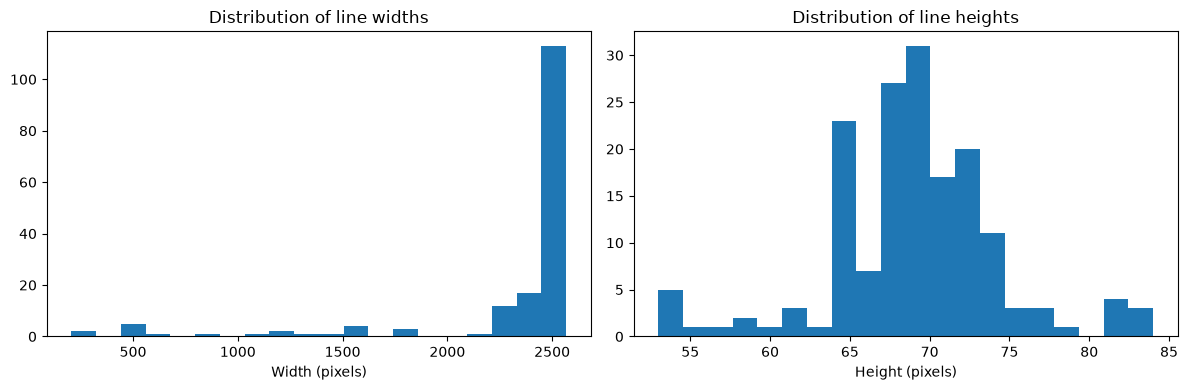

In [50]:
df["crop_width"] = df["x_max"] - df["x_min"]
df["crop_height"] = df["y_max"] - df["y_min"]

print(df[["crop_width", "crop_height"]].describe().to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df["crop_width"], bins=20)
axes[0].set_title("Distribution of line widths")
axes[0].set_xlabel("Width (pixels)")

axes[1].hist(df["crop_height"], bins=20)
axes[1].set_title("Distribution of line heights")
axes[1].set_xlabel("Height (pixels)")

plt.tight_layout()
plt.show()

In [51]:
df.to_csv(
    PROJECT_ROOT / "data/processed/line_metadata.csv",
    index=False,
    encoding="utf-8"
)

print("Final dataset saved.")
print("Pages:", df["page_id"].nunique())
print("Lines:", len(df))

Final dataset saved.
Pages: 4
Lines: 164


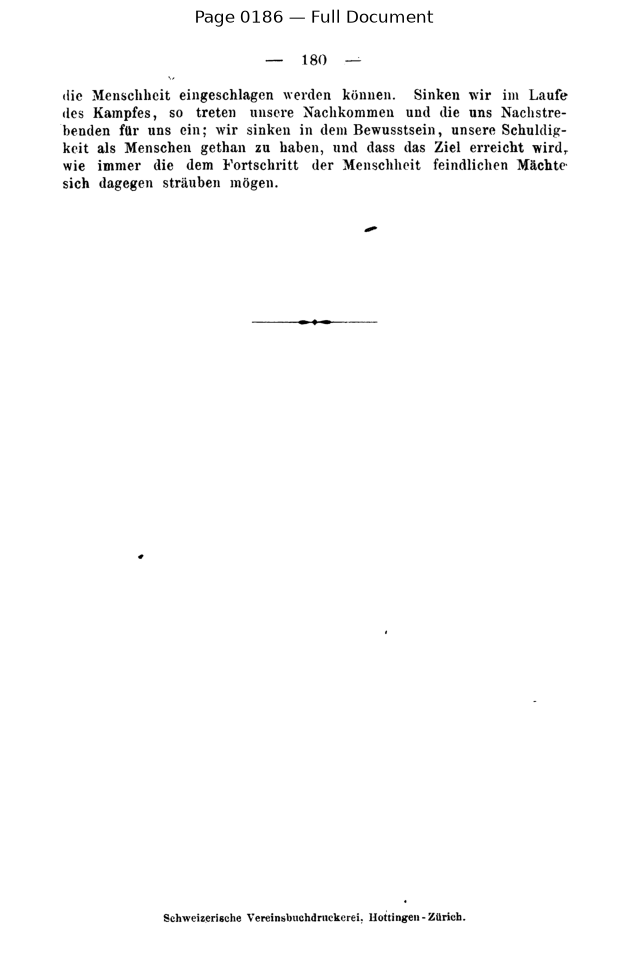

,line_id,ground_truth
156,l0,— 180 —
157,l1,die Menschheit eingeschlagen werden können. Si...
158,l2,"des Kampfes, so treten unsere Nachkommen und d..."
159,l3,benden für uns ein; wir sinken in dem Bewussts...
160,l4,"keit als Menschen gethan zu haben, und dass da..."
161,l5,wie immer die dem Fortschritt der Menschheit f...
162,l6,sich dagegen sträuben mögen.
163,l7,"Schweizerische Vereinsbuchdruckerei, Hottingen..."


In [52]:
page_id = "bebel_frau_1879_0186"

with Image.open(image_map[page_id]) as img:
    plt.figure(figsize=(8, 12))
    plt.imshow(img, cmap="gray")
    plt.title("Page 0186 — Full Document")
    plt.axis("off")
    plt.show()

print(df[df["page_id"] == page_id][
        ["line_id", "ground_truth"]
    ].to_string())